# Phase 2 — Model Comparison and Error Analysis

## Goal

Combine every final test result, compare models fairly, inspect errors, and provide
a reusable prediction example. All metrics below come from the same untouched
3,898-row test set.

In [1]:
from pathlib import Path
import os

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA = PROJECT_ROOT / "data" / "processed"
IMAGES = PROJECT_ROOT / "images"
MODELS = PROJECT_ROOT / "models"
RESULTS = PROJECT_ROOT / "results"

for folder in [IMAGES, MODELS, RESULTS]:
    folder.mkdir(parents=True, exist_ok=True)

os.environ["HF_HOME"] = str(PROJECT_ROOT / ".cache" / "huggingface")
print("Project folder:", PROJECT_ROOT)

Project folder: E:\AssDS\Project


In [2]:
import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
LABEL_MAP = {0: "Negative", 1: "Neutral", 2: "Positive"}

## 1. Combine final model results

In [3]:
classical = pd.read_csv(RESULTS / "classical_test_results.csv")
bilstm = pd.read_csv(RESULTS / "bilstm_test_results.csv")
bert = pd.read_csv(RESULTS / "bert_test_results.csv")

all_results = pd.concat([classical, bilstm, bert], ignore_index=True)
all_results = all_results.sort_values("macro_f1", ascending=False).reset_index(drop=True)
all_results.to_csv(RESULTS / "model_results.csv", index=False)

all_results.round(4)

,model,accuracy,macro_f1,weighted_f1,fit_seconds
0,Logistic Regression,0.6811,0.6767,0.6815,6.2503
1,Linear SVM,0.6570,0.6512,0.6568,5.9841
2,Naive Bayes,0.6398,0.6198,0.6317,0.8620
3,BiLSTM,0.5800,0.5738,0.5822,20.5894
4,BERT Tiny,0.5223,0.5141,0.5241,96.7861
5,Dummy Baseline,0.4333,0.2015,0.2620,0.2479


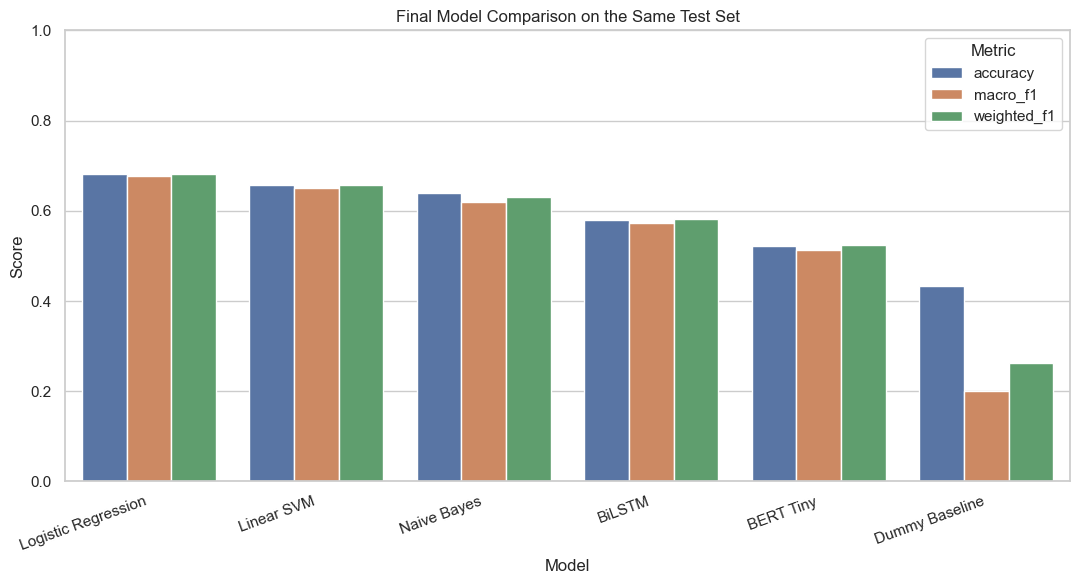

In [4]:
plot_data = all_results.melt(
    id_vars="model",
    value_vars=["accuracy", "macro_f1", "weighted_f1"],
    var_name="metric",
    value_name="score",
)

plt.figure(figsize=(11, 6))
ax = sns.barplot(data=plot_data, x="model", y="score", hue="metric")
plt.ylim(0, 1)
plt.title("Final Model Comparison on the Same Test Set")
plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(rotation=20, ha="right")
plt.legend(title="Metric")
plt.tight_layout()
plt.savefig(IMAGES / "09_final_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Select the best model by macro-F1

In [5]:
best_model_name = all_results.loc[0, "model"]
best_score = all_results.loc[0, "macro_f1"]

print("Best final model:", best_model_name)
print(f"Test macro-F1: {best_score:.4f}")
print("Macro-F1 is the main comparison metric because it treats every class equally.")

Best final model: Logistic Regression
Test macro-F1: 0.6767
Macro-F1 is the main comparison metric because it treats every class equally.


## 3. Error analysis

In [6]:
if best_model_name in ["Dummy Baseline", "Naive Bayes", "Logistic Regression", "Linear SVM"]:
    predictions = pd.read_csv(RESULTS / "classical_test_predictions.csv")
    predictions["predicted_label"] = predictions[best_model_name]
elif best_model_name == "BiLSTM":
    predictions = pd.read_csv(RESULTS / "bilstm_test_predictions.csv")
    predictions["predicted_label"] = predictions["BiLSTM"]
else:
    predictions = pd.read_csv(RESULTS / "bert_test_predictions.csv")
    predictions["predicted_label"] = predictions["BERT Tiny"]

predictions["predicted_sentiment"] = predictions["predicted_label"].map(LABEL_MAP)
errors = predictions[predictions["label"] != predictions["predicted_label"]].copy()
errors["word_count"] = errors["sentence"].fillna("").str.split().str.len()


def likely_difficulty(row):
    text = str(row["sentence"]).lower()
    if row["word_count"] <= 3:
        return "very short or ambiguous"
    if any(word in text.split() for word in ["lekin", "lakin", "magar", "but"]):
        return "mixed or contrasting opinion"
    if any(word in text.split() for word in ["movie", "film", "the", "is", "good", "bad"]):
        return "Urdu-English code-switching"
    if "!" in text or "?" in text:
        return "informal expression or punctuation"
    return "context, spelling variation, or possible label ambiguity"


errors["likely_difficulty"] = errors.apply(likely_difficulty, axis=1)
errors.to_csv(RESULTS / "all_best_model_errors.csv", index=False)

sample_groups = []
for _, group in errors.groupby("likely_difficulty"):
    sample_groups.append(group.sample(min(10, len(group)), random_state=42))

error_sample = pd.concat(sample_groups, ignore_index=True)
error_sample.to_csv(RESULTS / "error_analysis_sample.csv", index=False)

print("Total test errors:", len(errors))
errors["likely_difficulty"].value_counts().to_frame("count")

Total test errors: 1243


,count
likely_difficulty,
"context, spelling variation, or possible label ambiguity",926
Urdu-English code-switching,132
very short or ambiguous,89
mixed or contrasting opinion,48
informal expression or punctuation,48


In [7]:
pd.set_option("display.max_colwidth", 120)
error_sample[[
    "sentence", "sentiment", "predicted_sentiment", "likely_difficulty"
]].head(15)

,sentence,sentiment,predicted_sentiment,likely_difficulty
0,"Tahum paramount ne bhi film The Bell Boy banane ki peshkash ki, jise jerry ne qabool kar liya aur is film ki product...",Neutral,Positive,Urdu-English code-switching
1,Ghulam Ishaq Khan jabri retirement ke bad Peshwar mein gosh nashen ho gaye ow do saal musalsal bemar rahe,Negative,Neutral,Urdu-English code-switching
2,Is liye bohat choti umer mein Jaya Prada ko raqs o mauseeqi ki tarbiyat hasil karne bhej diya gaya,Neutral,Positive,Urdu-English code-switching
3,Pir Pagara Hur jamat ke sarbarah azeem dargah Pagara Gaddi ke sajjadah nasheen aur aik mumtaz politician ki hesiyat ...,Neutral,Positive,Urdu-English code-switching
4,Bad qismati se Pakistan team ke leye un ka intikab na ho saka,Neutral,Positive,Urdu-English code-switching
5,product is amazing . paper quality is also best . lkn bazar ke lehaz se price zyada hai ....,Neutral,Positive,Urdu-English code-switching
6,Is baat ka izhaar inho ne apne aik interview ke dauran kiya tha ke wo larhakpan he se apni janib uthne wali sataishi...,Neutral,Positive,Urdu-English code-switching
7,"Legend Naami film mein 52 saala jagpati Babu aur 53 saala Nanda Mori ke muqabl ehm kirdar ada kareingi,saal e rawan ...",Neutral,Positive,Urdu-English code-switching
8,Ab is ki siasat khatam,Negative,Neutral,Urdu-English code-switching
9,Arsal Lagta toh nhii tha Itna Actor Is Drame mai kamal ki acting ki hai.Isne.,Positive,Neutral,Urdu-English code-switching


The difficulty categories are transparent heuristics for organizing manual review;
they are not new ground-truth labels. They highlight short ambiguous text,
contrast words, code-switching, punctuation, and remaining context/spelling issues.

## 4. Beginner-friendly prediction example using the deployable classical model

In [8]:
classical_model = joblib.load(MODELS / "best_classical_model.joblib")


def predict_sentiment(text):
    numeric_prediction = int(classical_model.predict([text])[0])
    return LABEL_MAP[numeric_prediction]


examples = [
    "yeh movie bohat achi hai",
    "mujhe bilkul pasand nahi aya",
    "film kal release hui thi",
]

for example in examples:
    print(f"{example!r} -> {predict_sentiment(example)}")

'yeh movie bohat achi hai' -> Positive
'mujhe bilkul pasand nahi aya' -> Negative
'film kal release hui thi' -> Neutral


## 5. Final findings

In [9]:
best_row = all_results.iloc[0]
dummy_row = all_results[all_results["model"] == "Dummy Baseline"].iloc[0]
improvement = best_row["macro_f1"] - dummy_row["macro_f1"]

print(f"1. Best model: {best_row['model']}.")
print(f"2. Best accuracy: {best_row['accuracy']:.4f}.")
print(f"3. Best macro-F1: {best_row['macro_f1']:.4f}.")
print(f"4. Macro-F1 improvement over dummy baseline: {improvement:.4f}.")
print(f"5. Number of errors reviewed and exported: {len(error_sample)}.")
print("6. Roman Urdu spelling variation and short ambiguous messages remain important challenges.")

1. Best model: Logistic Regression.
2. Best accuracy: 0.6811.
3. Best macro-F1: 0.6767.
4. Macro-F1 improvement over dummy baseline: 0.4751.
5. Number of errors reviewed and exported: 50.
6. Roman Urdu spelling variation and short ambiguous messages remain important challenges.


## Conclusion

Phase 2 now contains classical, deep-learning, and transformer experiments with a
shared test set, class-aware metrics, confusion matrices, model comparison, saved
artifacts, error analysis, and an inference example. An LLM prompting experiment
was left as an optional future extension because it would require an external API
and would not be directly reproducible from this repository.